# 03 · Training-only exploratory data analysis
Every statistic and plot on this page uses the **training period only** (the test rows are locked). Pearson and Spearman correlations of every candidate
predictor with the target and the feature–feature redundancy are computed here; nothing from the test period enters.
**Code.** `Experiment.stage_training_data` and `Experiment.stage_eda` (`src/experiment.py`), plots in `src/plotting.py`. The figures below are the stored outputs of `python run_all.py`.

| # | Required item | Where |
|---|---|---|
| 1 | PM2.5 distribution | Figure 2 |
| 2 | PM2.5 over time | Figure S1 |
| 3, 4 | PM2.5 by hour / by month | Figure 3 (a, b; c: weekday) |
| 5–10 | PM2.5 vs PM10, NO2, CO, O3, temperature, dew point (humidity proxy) | Figure S2 |
| 11–13 | correlation heatmap, Spearman, Pearson | Figure 4 (both), Figure 5, table S03 |
| 14 | feature–feature redundancy | Figure S5 (VIF, clustered correlations), log line *raw-variable redundancy* |
| + | wind effects, autocorrelation, missing-value policy | Figures S3, S6, S4 |

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Target distribution and temporal structure

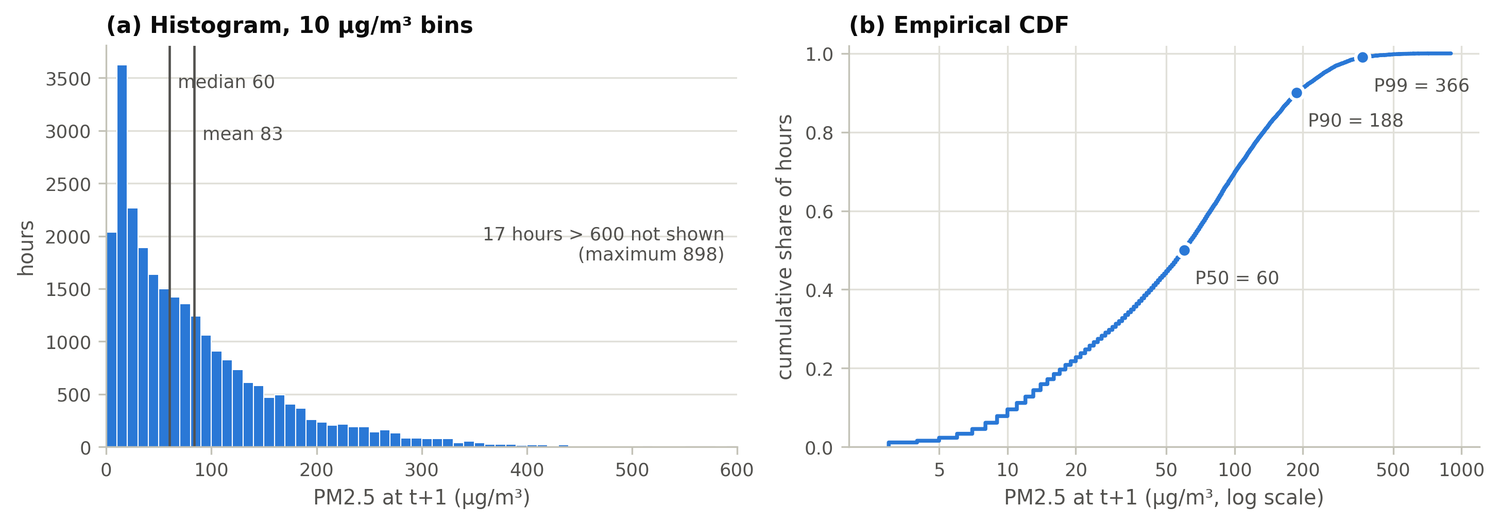

*Distribution of the target (PM2.5 one hour ahead) in the 26,000 usable training rows. The series is right-skewed (skewness 1.92): median 60, mean 83, 99th percentile 366 and maximum 898 µg/m³. The heavy tail makes squared-error metrics (RMSE) much larger than MAE.*

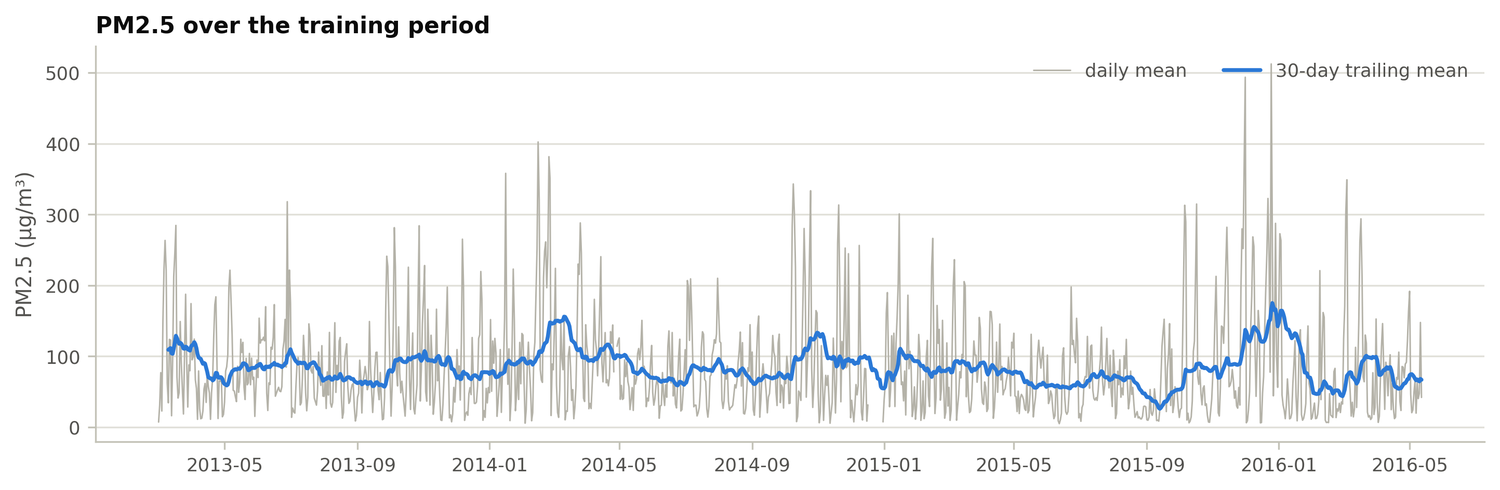

*Daily mean PM2.5 in the training period (2013-03-01 to 2016-05-12) with a 30-day trailing mean (past data only): daily means range from 5 to 512 µg/m³ with a strong seasonal cycle and irregular multi-day episodes.*

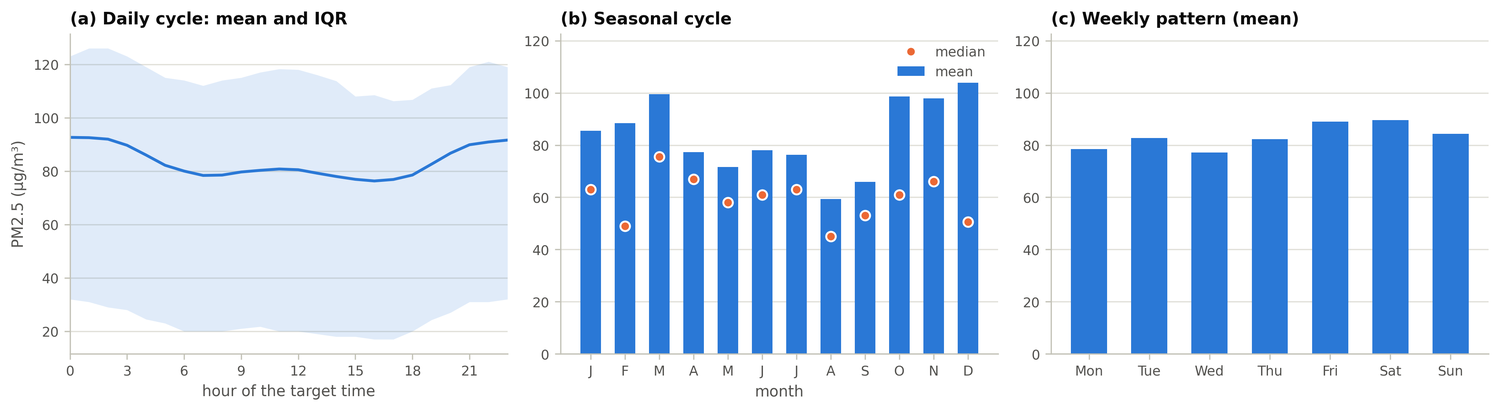

*Training-only temporal structure of the target (clock of the target hour). (a) Daily cycle: the hourly mean ranges from 76 (16:00) to 93 µg/m³ (0:00), a spread of 20 % of the overall mean; the band is the inter-quartile range. (b) Seasonal cycle: monthly means from 59 (August) to 104 µg/m³ (December); dots are medians. (c) Weekly pattern: weekday mean 81.9 vs weekend 87.0 µg/m³. These patterns motivate the cyclical temporal features (H3).*

In [2]:
fig("figure_02_pm25_distribution")
fig("figure_S01_pm25_over_time")
fig("figure_03_pm25_temporal_pattern")

## 2. Relation to pollutants, meteorology and wind

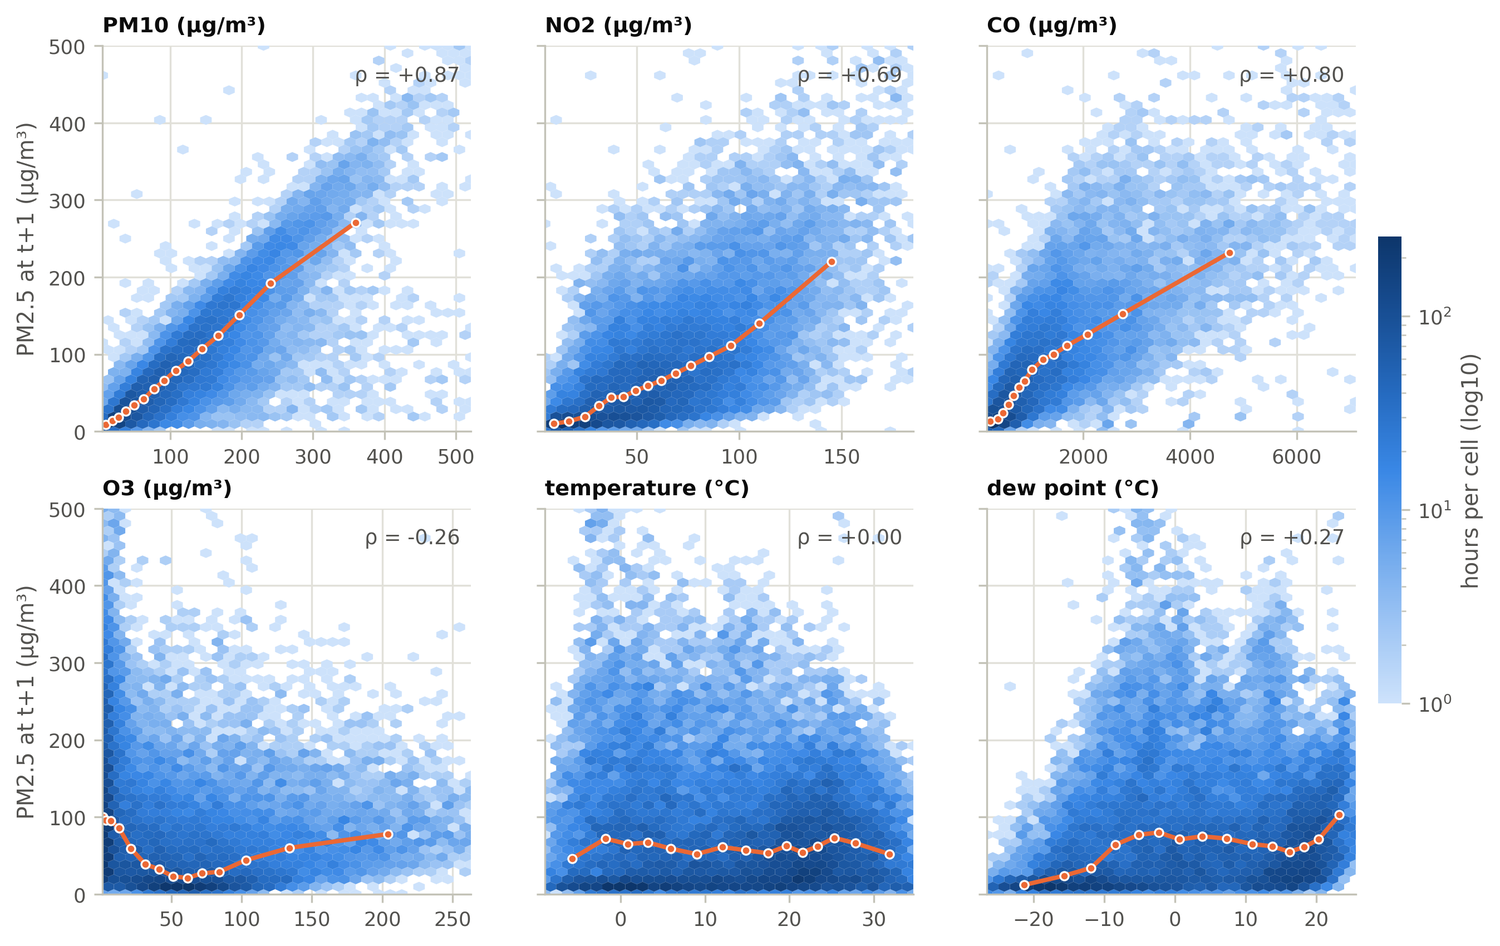

*Next-hour PM2.5 against PM10, NO2, CO, O3, temperature and dew point (training rows; y clipped at 500 µg/m³). Hexagons: density; orange: median within 15 equal-count bins; ρ = Spearman correlation (PM10 +0.87, NO2 +0.69, CO +0.80, O3 -0.26, TEMP +0.00, DEWP +0.27). Data-quality caveat: PM10 equals PM2.5(t) exactly in 22.7 % of the hours and is even lower in 4.4 %, which is physically inconsistent.*

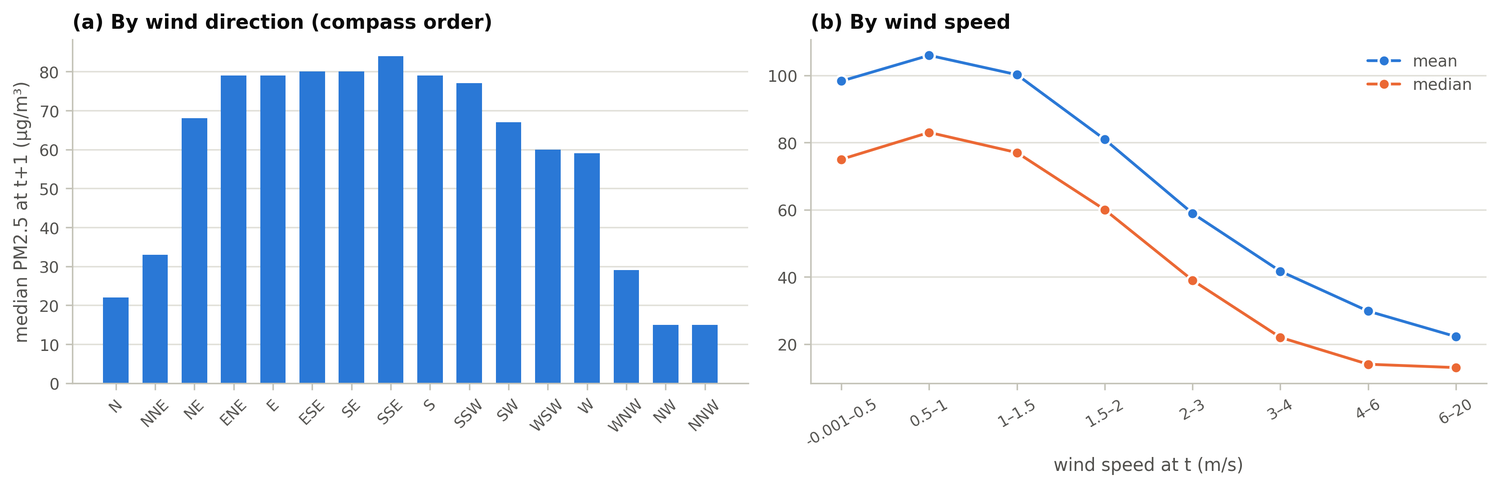

*Training-only wind effects. (a) Median next-hour PM2.5 by wind direction: lowest for NNW (15) and NW (15), highest for SSE (84) µg/m³; direction matters, hence one-hot encoding without an artificial ordering. (b) Mean and median PM2.5 by wind speed at t: the mean is highest in the 0.5-1 m/s bin (106) and lowest in the 6-20 m/s bin (22 µg/m³), i.e. ventilation lowers PM2.5, which motivates the wind x PM interactions.*

In [3]:
fig("figure_S02_target_vs_pollutants_meteorology")
fig("figure_S03_wind_effects")

## 3. Correlations with the target (Pearson and Spearman, training rows only)

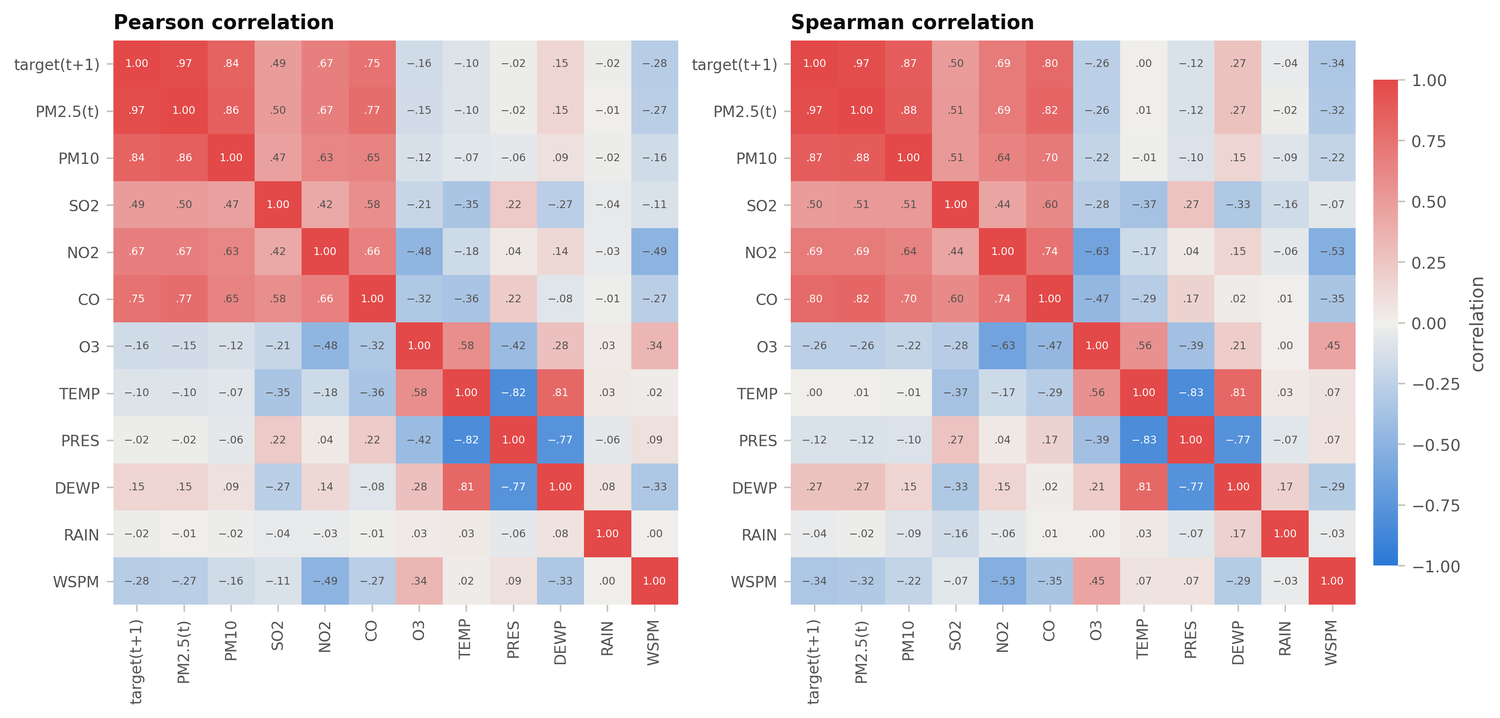

*Training-only Pearson (left) and Spearman (right) correlation matrices of the raw measurements and the target (next-hour PM2.5). Pearson correlation with the target: PM2.5(t) 0.97, PM10 0.84, CO 0.75, NO2 0.67; TEMP and DEWP correlate at 0.81 with each other and PM10 with PM2.5(t) at 0.86.*

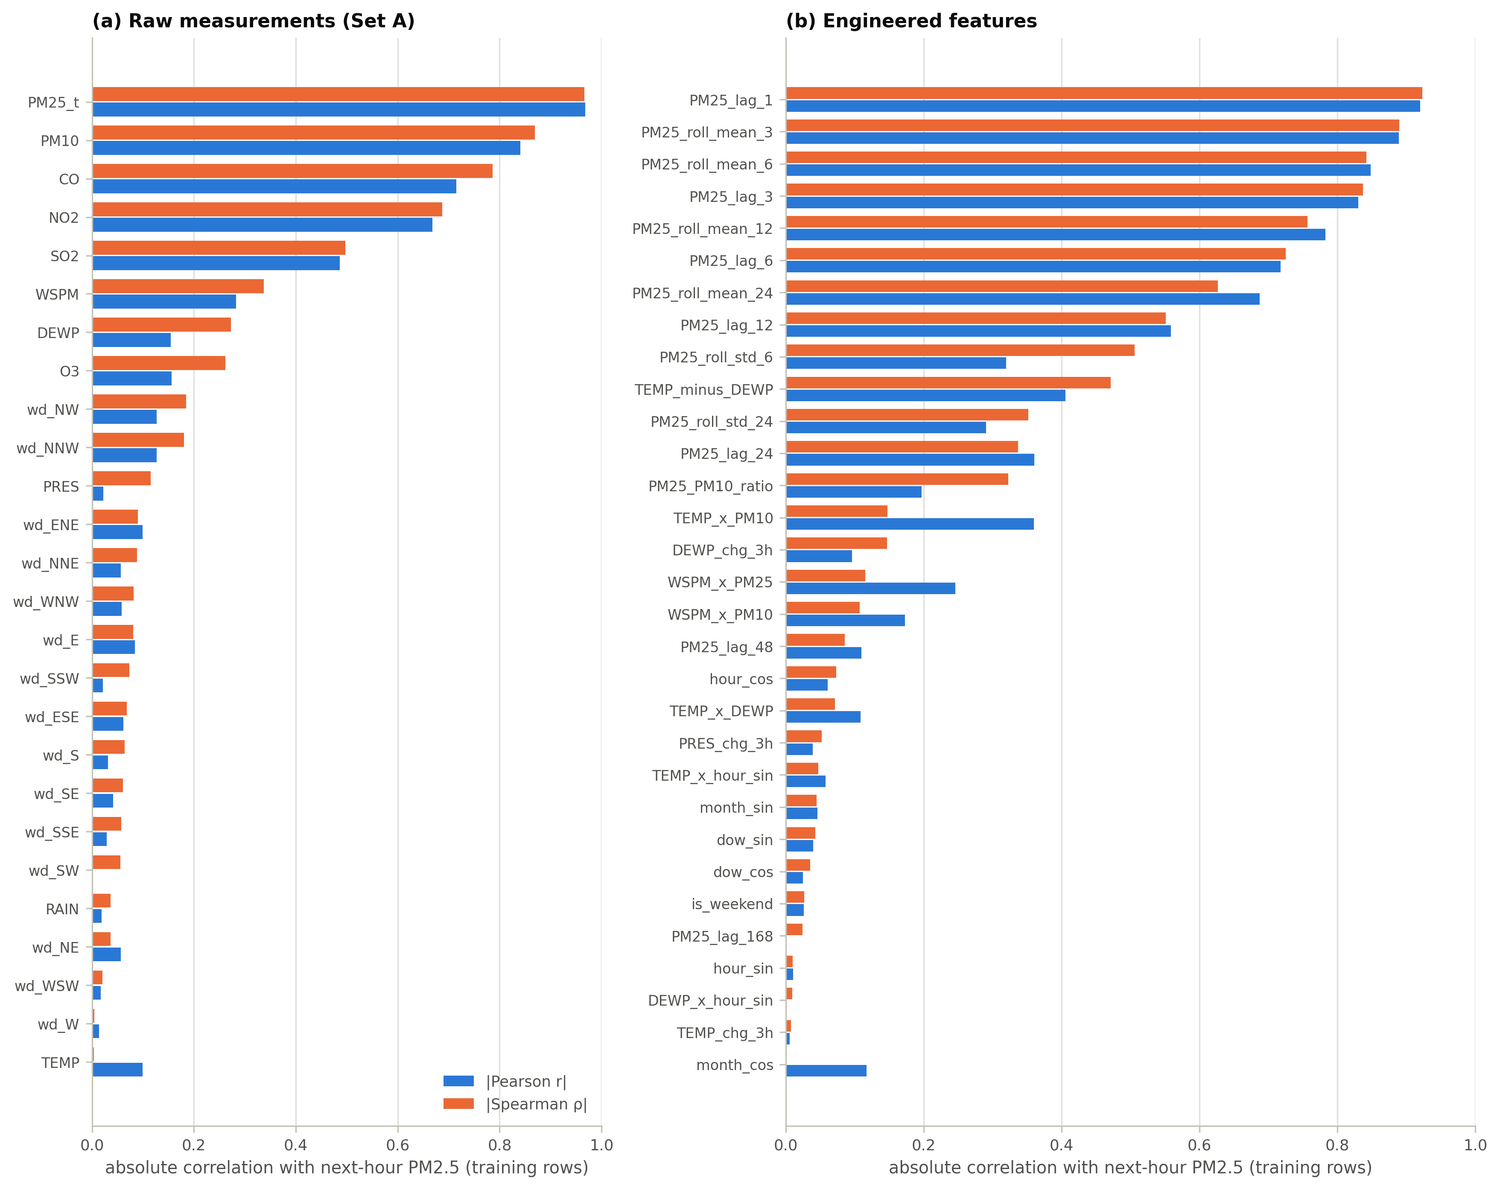

*Absolute Pearson and Spearman correlation of every candidate feature with the next-hour PM2.5 (training rows only). The current PM2.5 (Spearman ρ = 0.97), the first lag (0.92) and the short rolling means (ρ ≥ 0.84 for the 3- and 6-hour windows) rank highest; among the other raw measurements PM10 (0.87), CO (0.79) and NO2 (0.69) are strongest. Temperature (+0.00), pressure (-0.12) and rain (-0.04) are only weakly related, and 13 of the 15 wind-direction dummies have |ρ| < 0.10.*

,feature,set,group,pearson,spearman
0,PM25_t,raw,current PM2.5,0.968,0.966
1,PM25_lag_1,engineered,lag,0.920,0.923
2,PM25_roll_mean_3,engineered,rolling,0.889,0.890
3,PM10,raw,pollutants,0.841,0.869
4,PM25_roll_mean_6,engineered,rolling,0.848,0.842
5,PM25_lag_3,engineered,lag,0.830,0.837
6,CO,raw,pollutants,0.715,0.786
7,PM25_roll_mean_12,engineered,rolling,0.782,0.757
8,PM25_lag_6,engineered,lag,0.718,0.725
9,NO2,raw,pollutants,0.668,0.687


In [4]:
fig("figure_04_correlation_heatmap_train")
fig("figure_05_feature_target_correlation_ranking")
display(table("table_S03_feature_target_association").head(20).round(3))

## 4. Memory of the series, missing values and redundancy

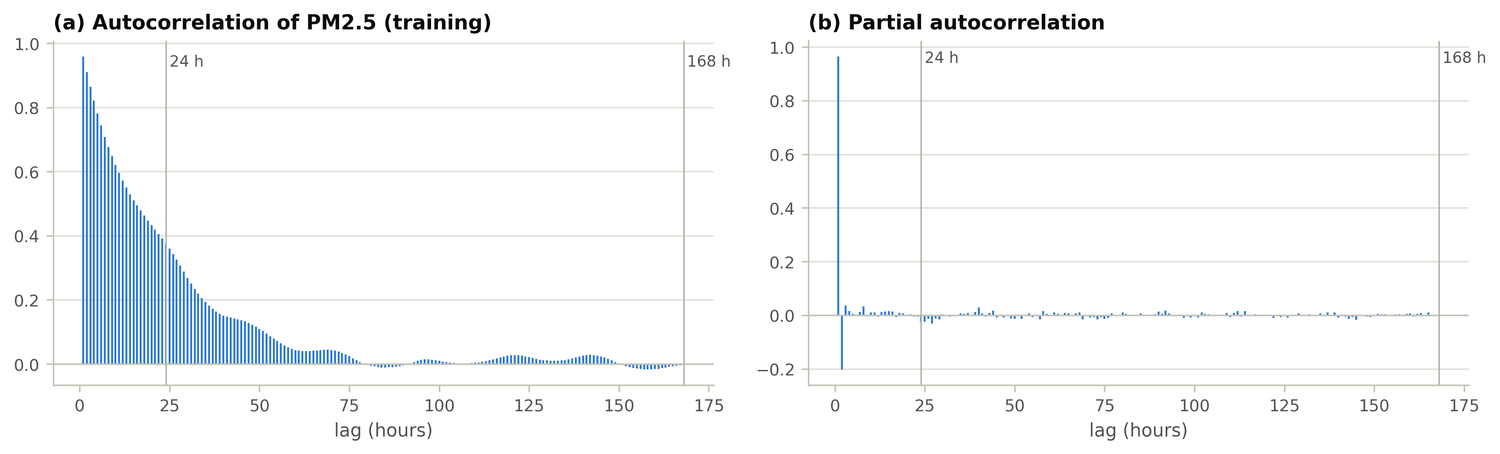

*Autocorrelation and partial autocorrelation of hourly PM2.5 (training rows). The autocorrelation falls from 0.96 at lag 1 to 0.38 at 24 h and -0.003 at one week. The partial autocorrelation is dominated by lag 1 (0.97) with a negative lag-2 term (-0.20); beyond lag 2 no partial autocorrelation exceeds 0.04 in absolute value (lag 24: -0.026, lag 168: -0.002), so the daily and weekly lags are expected to add little once the most recent hours are known.*

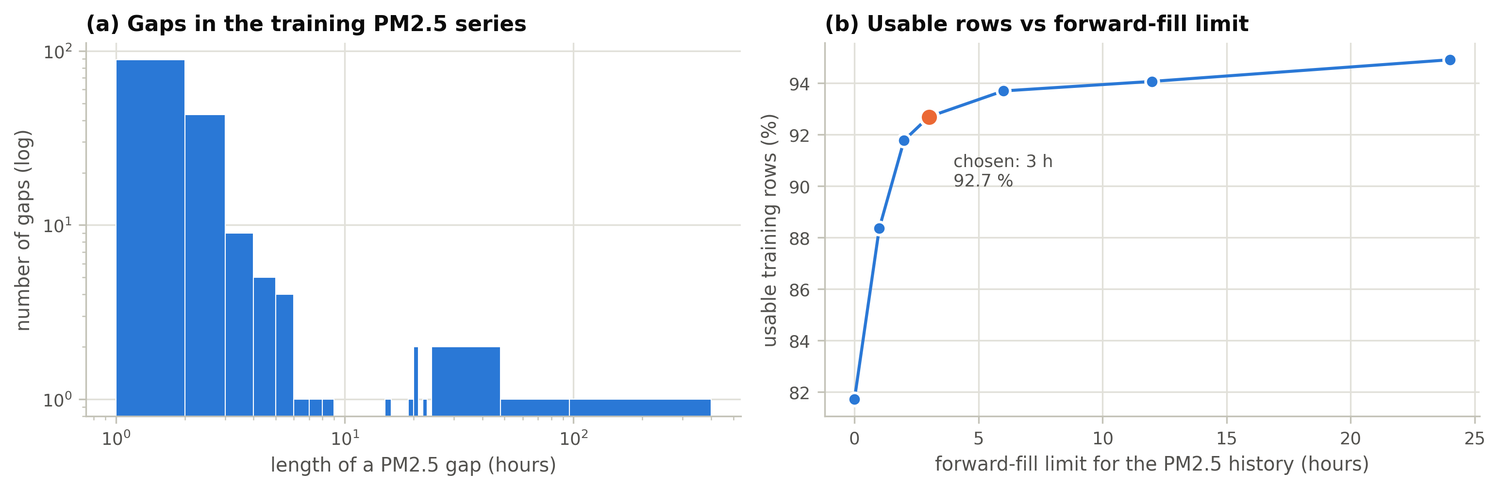

*Missing-value policy (training rows). (a) The PM2.5 series has 162 gaps; 87 % last at most 3 hours, the longest lasts 343 hours. (b) Causally forward-filling the PM2.5 history over gaps of up to 3 hours keeps 92.7 % of the training hours (no filling: 81.7 %); a 12-hour limit would add only 1.4 points and a 24-hour limit 2.2. The target is never filled; rows with unusable history are excluded identically for every model.*

,forward_fill_limit_hours,usable_training_rows,usable_share_pct
0,0,22921,81.7
1,1,24786,88.4
2,2,25744,91.8
3,3,26000,92.7
4,6,26282,93.7
5,12,26386,94.1
6,24,26622,94.9


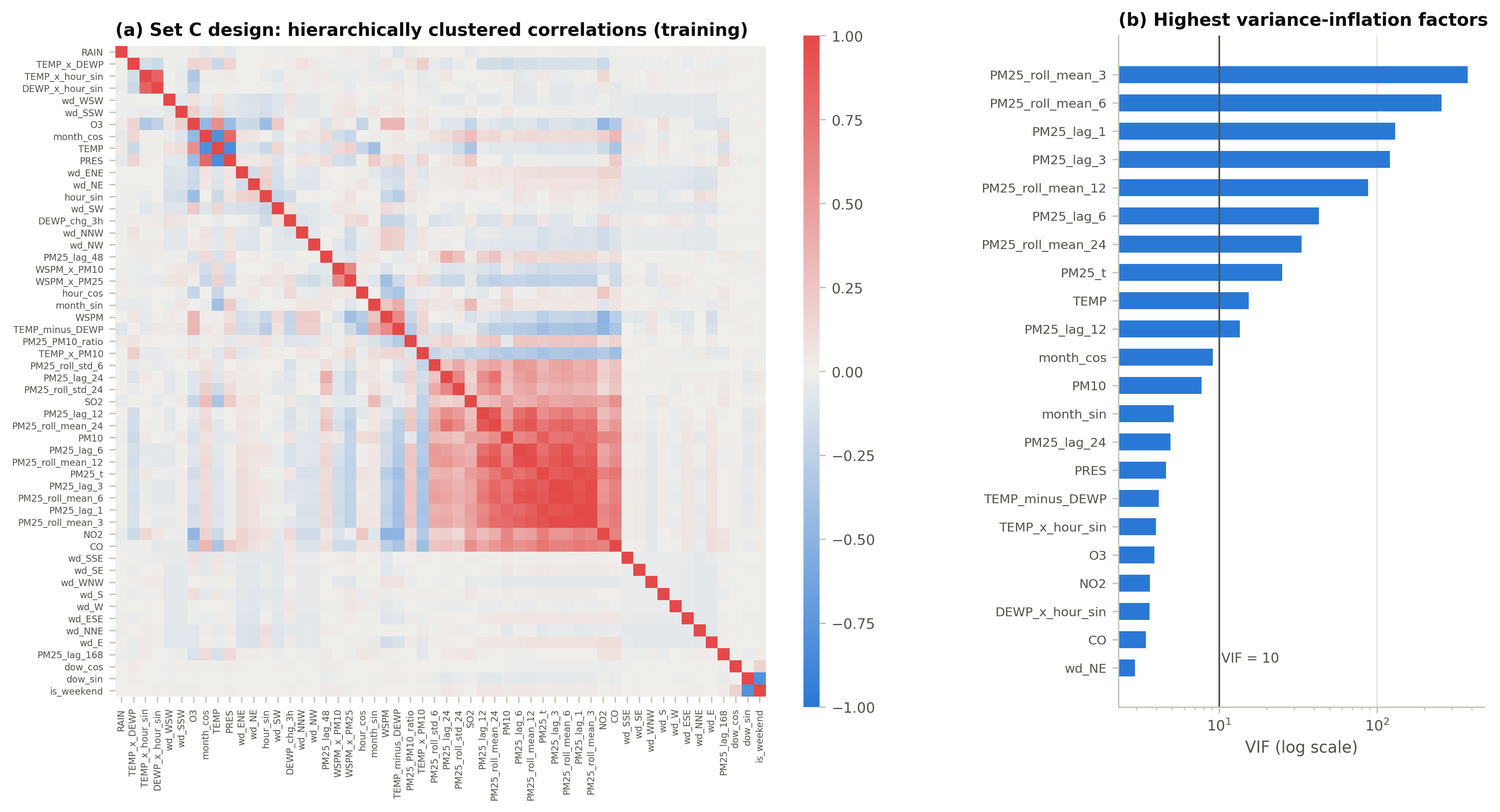

*Redundancy of the Set C training design (54 columns). (a) Pearson correlation matrix ordered by hierarchical clustering: the PM2.5 history (current value, lags, rolling means) forms one tightly correlated block that is also related to PM10, NO2 and CO. (b) The 22 columns with the highest variance-inflation factor (log axis): 10 columns exceed VIF = 10 (maximum 377 for PM25_roll_mean_3); the 10 largest are PM25_roll_mean_3, PM25_roll_mean_6, PM25_lag_1, PM25_lag_3, PM25_roll_mean_12, PM25_lag_6, PM25_roll_mean_24, PM25_t, TEMP, PM25_lag_12. Such collinearity makes individual history coefficients unstable and motivates penalised regression.*

In [5]:
fig("figure_S06_autocorrelation")
fig("figure_S04_missing_values_policy")
display(table("table_S02_missing_value_policy").round(1))
fig("figure_S05_feature_redundancy")

## 5. Numbers logged by the EDA stage

In [6]:
log_grep(r"^training    :|^POLICY|^usable rows|^target \(next-hour|^data quality|^autocorrelation of|^top-12|^strongest raw|^raw-variable|^daily cycle|^median target by wind|^ventilation")

training    : 28,050 hours; PM2.5 missing 818 (2.92 %) in 162 gaps (median 1 h, 90th pct 4 h, max 343 h); 87 % of the gaps last <= 3 h
POLICY      : (1) the TARGET is never imputed - hours whose PM2.5(t+1) is missing are dropped; (2) the CURRENT PM2.5(t) must be observed (persistence needs it); (3) PM2.5 HISTORY features (lags, rolling) use a causal last-observation-carried-forward over gaps <= 3 h, longer gaps make the row unusable; (4) other pollutants / meteorology / wind direction are imputed INSIDE each training fold (SimpleImputer: median / mo
usable rows : 26,000 of 28,050 training hours (92.7 %): missing target 818, observed target but missing current PM2.5 162, insufficient history 1232   [first 168 hours have no complete history]
target (next-hour PM2.5, usable training rows n=26,000): mean 83.4 median 60 std 81.2 min 3 max 898 skew 1.92; P25/P75/P95/P99 = [23.0, 116.0, 247.0, 366.0]
data quality: PM10 == PM2.5(t) exactly in 22.7 % of the usable training hours (5904 of 26000)

**Data-quality observation.** `PM10` equals `PM2.5(t)` exactly in a large share of the hours and is even smaller in a few, which is physically inconsistent (PM10 contains PM2.5).
The share is printed above (*data quality*). PM10-based features and the PM2.5/PM10 ratio therefore have to be read with care.